# Hidden Markov Model

A sequence model where the thing you care about is **hidden**. A hidden state hops around a Markov chain, and at every step it emits a visible symbol. You see only the symbols (umbrella, no umbrella…) and want to reason about the states (rain, sun…). Used for speech, part-of-speech tagging, gene finding, regime detection.

## Parameters

| | meaning |
|---|---|
| `pi[i]` | probability the chain starts in state `i` |
| `A[i, j]` | probability of moving from state `i` to `j` |
| `B[i, k]` | probability that state `i` emits symbol `k` |

## The three classic problems — one method each

| Question | Method | Algorithm |
|---|---|---|
| How likely is this sequence? | `score(obs)` | **Forward**: `αₜ(j) = [Σᵢ αₜ₋₁(i) A[i,j]] · B[j, oₜ]` — sums over all `Nᵀ` paths in `O(T·N²)` |
| What states most likely produced it? | `decode(obs)` | **Viterbi**: same recursion with `max` instead of `Σ`, then trace back |
| Learn the parameters from sequences | `fit(seqs)` | **Baum-Welch** (EM): E step uses forward-backward to get `γₜ(i)` = P(state `i` at `t` \| everything) and `ξₜ(i,j)`; M step re-estimates `pi, A, B` from expected counts |

`predict_proba(obs)` gives `γ` itself — the soft version of Viterbi. `sample(length)` generates data from the model.

Messages are rescaled at every time step (`cₜ`) so a 20 000-step sequence does not underflow to 0; the log-likelihood is `Σ log cₜ`.

## Things to know

- Baum-Welch **never decreases** the likelihood (a test checks it) but only finds a *local* optimum, so `fit` restarts `n_init` times and keeps the best.
- Learned states come back in arbitrary order: state 0 is not necessarily your "sunny" — match by looking at `B`.
- The tests verify forward, Viterbi and posteriors against **brute-force enumeration of every state path** on a tiny model; the demo checks them against `hmmlearn` if it is installed (optional, `pip install hmmlearn`).

`ponytail:` discrete symbols only. Gaussian emissions (continuous observations) would swap `B[i, k]` for a density per state; the forward/Viterbi/EM structure is identical.

## Usage

```python
# (the class is defined in the Implementation section below)

hmm = HiddenMarkovModel(n_states=2, n_symbols=3).fit(sequences)   # list of int arrays, or one array
hmm.A_, hmm.B_, hmm.pi_
hmm.score(obs)           # log-likelihood
hmm.decode(obs)          # (most likely states, log-prob)
hmm.predict_proba(obs)   # P(state_t | whole sequence)
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


class HiddenMarkovModel:
    """Discrete-observation HMM: a hidden Markov chain of states that emits visible symbols.

    Parameters
        pi[i]   = P(first state is i)
        A[i, j] = P(next state is j | state is i)       (rows sum to 1)
        B[i, k] = P(emit symbol k | state is i)         (rows sum to 1)

    Three classic problems, one method each:
      score(obs)    "how likely is this sequence?"      forward algorithm
      decode(obs)   "which states most likely made it?" Viterbi (best single path)
      fit(seqs)     "learn pi, A, B from sequences"      Baum-Welch (EM with forward-backward)
    plus predict_proba(obs) = posterior P(state_t | whole sequence) and sample().

    Forward/backward messages are rescaled at every step (c_t) so long sequences do not underflow;
    log-likelihood is the sum of log c_t.

    ponytail: Baum-Welch only finds a local optimum, so it restarts `n_init` times from random
    parameters and keeps the best; no priors / smoothing beyond a tiny floor."""

    def __init__(self, n_states=2, n_symbols=2, n_iter=100, tol=1e-6, n_init=5, random_state=0):
        self.n_states = n_states
        self.n_symbols = n_symbols
        self.n_iter = n_iter
        self.tol = tol
        self.n_init = n_init
        self.random_state = random_state

    # ----- inference -----
    def _forward(self, obs):
        T = len(obs)
        alpha = np.zeros((T, self.n_states))
        c = np.zeros(T)
        alpha[0] = self.pi_ * self.B_[:, obs[0]]
        c[0] = alpha[0].sum()
        alpha[0] /= c[0]
        for t in range(1, T):
            alpha[t] = (alpha[t - 1] @ self.A_) * self.B_[:, obs[t]]
            c[t] = alpha[t].sum()
            alpha[t] /= c[t]
        return alpha, c

    def _backward(self, obs, c):
        T = len(obs)
        beta = np.ones((T, self.n_states))
        for t in range(T - 2, -1, -1):
            beta[t] = self.A_ @ (self.B_[:, obs[t + 1]] * beta[t + 1]) / c[t + 1]
        return beta

    def score(self, obs):
        """log P(obs)."""
        return np.log(self._forward(np.asarray(obs))[1]).sum()

    def predict_proba(self, obs):
        """P(state_t = i | all observations), shape (T, n_states)."""
        obs = np.asarray(obs)
        alpha, c = self._forward(obs)
        return alpha * self._backward(obs, c)

    def decode(self, obs):
        """Viterbi: the single most likely state sequence, and its log-probability."""
        obs = np.asarray(obs)
        T = len(obs)
        logA, logB = np.log(self.A_ + 1e-300), np.log(self.B_ + 1e-300)
        delta = np.log(self.pi_ + 1e-300) + logB[:, obs[0]]
        back = np.zeros((T, self.n_states), dtype=int)
        for t in range(1, T):
            scores = delta[:, None] + logA            # [from, to]
            back[t] = scores.argmax(axis=0)
            delta = scores.max(axis=0) + logB[:, obs[t]]
        path = [int(delta.argmax())]
        for t in range(T - 1, 0, -1):
            path.append(int(back[t][path[-1]]))
        return np.array(path[::-1]), delta.max()

    def sample(self, length, random_state=None):
        rng = np.random.default_rng(random_state)
        states, obs = np.zeros(length, dtype=int), np.zeros(length, dtype=int)
        s = rng.choice(self.n_states, p=self.pi_)
        for t in range(length):
            states[t] = s
            obs[t] = rng.choice(self.n_symbols, p=self.B_[s])
            s = rng.choice(self.n_states, p=self.A_[s])
        return states, obs

    # ----- learning -----
    def fit(self, sequences):
        """Baum-Welch on one sequence or a list of sequences of integer symbols 0..n_symbols-1."""
        if np.ndim(sequences[0]) == 0:
            sequences = [sequences]
        sequences = [np.asarray(s) for s in sequences]
        rng = np.random.default_rng(self.random_state)
        best = None
        for _ in range(self.n_init):
            self.pi_ = rng.dirichlet(np.ones(self.n_states))
            self.A_ = rng.dirichlet(np.ones(self.n_states), size=self.n_states)
            self.B_ = rng.dirichlet(np.ones(self.n_symbols), size=self.n_states)
            history = self._baum_welch(sequences)
            if best is None or history[-1] > best[0]:
                best = (history[-1], self.pi_, self.A_, self.B_, history)
        _, self.pi_, self.A_, self.B_, self.log_likelihoods_ = best
        return self

    def _baum_welch(self, sequences):
        K, S, history = self.n_symbols, self.n_states, []
        for _ in range(self.n_iter):
            pi = np.zeros(S)
            A_num, A_den = np.zeros((S, S)), np.zeros(S)
            B_num = np.zeros((S, K))
            total = 0.0
            for obs in sequences:                                    # E step
                alpha, c = self._forward(obs)
                beta = self._backward(obs, c)
                gamma = alpha * beta
                total += np.log(c).sum()
                pi += gamma[0]
                for t in range(len(obs) - 1):
                    A_num += alpha[t][:, None] * self.A_ * (self.B_[:, obs[t + 1]] * beta[t + 1])[None, :] / c[t + 1]
                A_den += gamma[:-1].sum(axis=0)
                for k in range(K):
                    B_num[:, k] += gamma[obs == k].sum(axis=0)
            history.append(total)
            eps = 1e-10                                              # M step (tiny floor avoids 0/0)
            self.pi_ = (pi + eps) / (pi + eps).sum()
            self.A_ = (A_num + eps) / (A_num + eps).sum(axis=1, keepdims=True)
            self.B_ = (B_num + eps) / (B_num + eps).sum(axis=1, keepdims=True)
            if len(history) > 1 and abs(history[-1] - history[-2]) < self.tol:
                break
        return history

## See it work

### 1. Recovering hidden states

A two-state weather model (sunny/rainy) that emits what you see (walk / shop / umbrella). We generate a sequence, then use only the observations to infer the hidden weather in two ways: **Viterbi** (the single most likely state sequence) and the **posterior** `P(rainy | all observations)` from forward-backward.

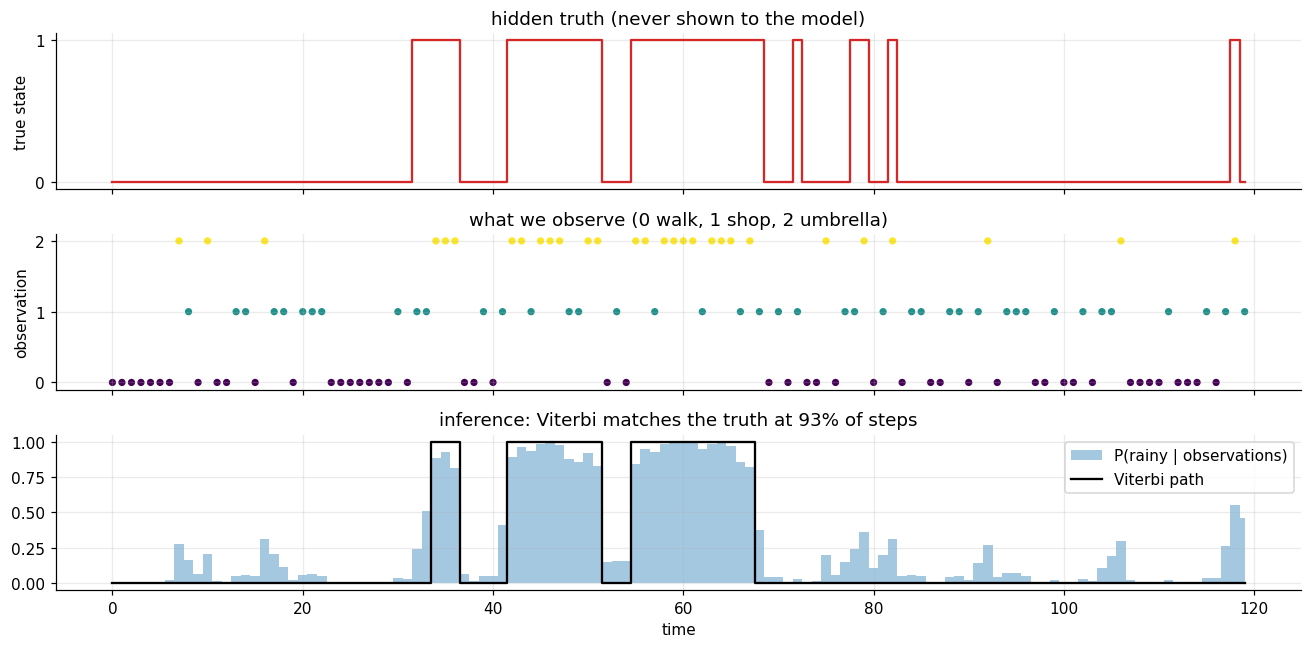

In [3]:
truth = HiddenMarkovModel(n_states=2, n_symbols=3)
truth.pi_ = np.array([0.7, 0.3]); truth.A_ = np.array([[0.9, 0.1], [0.2, 0.8]]); truth.B_ = np.array([[0.6, 0.3, 0.1], [0.05, 0.25, 0.7]])
states, obs = truth.sample(120, random_state=3)
path, _ = truth.decode(obs); post = truth.predict_proba(obs)[:, 1]
fig, axes = plt.subplots(3, 1, figsize=(12, 6), sharex=True)
axes[0].step(range(len(obs)), states, where="mid", color="C3"); axes[0].set(ylabel="true state", yticks=[0, 1], title="hidden truth (never shown to the model)")
axes[1].scatter(range(len(obs)), obs, c=obs, cmap="viridis", s=14); axes[1].set(ylabel="observation", yticks=[0, 1, 2], title="what we observe (0 walk, 1 shop, 2 umbrella)")
axes[2].fill_between(range(len(obs)), post, step="mid", alpha=0.4, label="P(rainy | observations)"); axes[2].step(range(len(obs)), path, where="mid", color="k", label="Viterbi path")
axes[2].legend(loc="upper right"); axes[2].set(xlabel="time", title=f"inference: Viterbi matches the truth at {(path == states).mean():.0%} of steps")
plt.tight_layout(); plt.show()

### 2. Learning the model with Baum-Welch

Given only observations, EM (forward-backward for the E-step) estimates the transition matrix `A` and emission matrix `B`. The log-likelihood climbs monotonically; the learned matrices land close to the truth (the labelling of states is arbitrary, so we align them first).

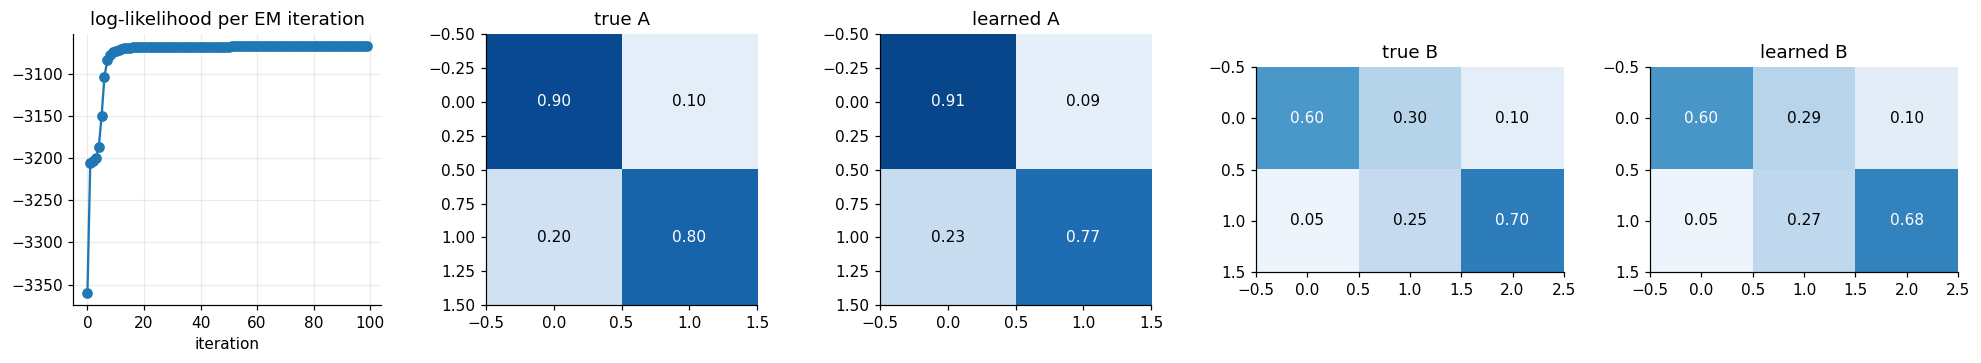

In [4]:
_, long_obs = truth.sample(3000, random_state=0)
fit = HiddenMarkovModel(n_states=2, n_symbols=3, random_state=0).fit(long_obs)
order = [0, 1] if fit.B_[0, 2] < fit.B_[1, 2] else [1, 0]
A_fit, B_fit = fit.A_[np.ix_(order, order)], fit.B_[order]

def heat(ax, M, title):
    ax.imshow(M, vmin=0, vmax=1, cmap="Blues"); ax.grid(False); ax.set_title(title)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]): ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", color="w" if M[i, j] > 0.5 else "k")
fig, axes = plt.subplots(1, 5, figsize=(18, 3.4))
axes[0].plot(fit.log_likelihoods_, "o-"); axes[0].set(title="log-likelihood per EM iteration", xlabel="iteration")
heat(axes[1], truth.A_, "true A"); heat(axes[2], A_fit, "learned A"); heat(axes[3], truth.B_, "true B"); heat(axes[4], B_fit, "learned B")
plt.tight_layout(); plt.show()

### 3. Why work in scaled/log space

The probability of a long observation sequence is a product of thousands of numbers below 1, which underflows to exactly `0.0` in floating point. The implementation rescales the forward messages at every step, so the log-likelihood stays finite:

In [5]:
_, very_long = truth.sample(20000, random_state=1)
naive = 1.0
for t, o in enumerate(very_long[:2000]): naive *= 0.5 * truth.B_[:, o].max()                 # crude product of per-step probabilities
print("naive product of probabilities over 2000 steps:", naive)
print("scaled forward algorithm, log-likelihood over 20000 steps:", round(truth.score(very_long), 1))

naive product of probabilities over 2000 steps: 0.0
scaled forward algorithm, log-likelihood over 20000 steps: -20453.1


## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [6]:
import numpy as np

# Classic example: hidden weather (0=sunny, 1=rainy) decides what you see (0=walk, 1=shop, 2=umbrella)
truth = HiddenMarkovModel(n_states=2, n_symbols=3)
truth.pi_ = np.array([0.7, 0.3])
truth.A_ = np.array([[0.85, 0.15], [0.30, 0.70]])
truth.B_ = np.array([[0.60, 0.30, 0.10], [0.05, 0.25, 0.70]])
states, obs = truth.sample(3000, random_state=0)

# 1) Viterbi: recover the hidden weather from what was observed
path, _ = truth.decode(obs)
print("Viterbi recovers the true hidden state at %.1f%% of days (guessing the majority: %.1f%%)"
      % (100 * (path == states).mean(), 100 * max((states == 0).mean(), (states == 1).mean())))

# 2) Baum-Welch: learn the model from the observations alone (state labels are never shown)
fit = HiddenMarkovModel(n_states=2, n_symbols=3, random_state=0).fit(obs)
order = [0, 1] if fit.B_[0, 2] < fit.B_[1, 2] else [1, 0]      # state numbering is arbitrary: sort by umbrella rate
print("learned transition matrix:\n", fit.A_[np.ix_(order, order)].round(2), "\n true:\n", truth.A_)
print("learned emissions:\n", fit.B_[order].round(2), "\n true:\n", truth.B_)
print("log-likelihood: learned=%.1f  true model=%.1f" % (fit.score(obs), truth.score(obs)))

# 3) cross-check against hmmlearn when it is installed (pip install hmmlearn)
try:
    from hmmlearn.hmm import CategoricalHMM

    ref = CategoricalHMM(n_components=2)
    ref.startprob_, ref.transmat_, ref.emissionprob_ = truth.pi_, truth.A_, truth.B_
    X = obs.reshape(-1, 1)
    assert np.isclose(truth.score(obs), ref.score(X))
    assert np.allclose(truth.predict_proba(obs), ref.predict_proba(X))
    assert (truth.decode(obs)[0] == ref.predict(X)).all()
    print("score, posterior probabilities and Viterbi path identical to hmmlearn")

    # EM finds local optima, so give hmmlearn the same 5 random restarts as ours and keep its best
    runs = [CategoricalHMM(n_components=2, n_iter=100, tol=1e-6, random_state=seed, n_features=3).fit(X) for seed in range(5)]
    best = max(r.score(X) for r in runs)
    print("after fitting: ours=%.1f hmmlearn(best of 5)=%.1f" % (fit.score(obs), best))
    assert abs(fit.score(obs) - best) < 1
except ImportError:
    print("hmmlearn not installed; skipped the comparison")

Viterbi recovers the true hidden state at 86.4% of days (guessing the majority: 66.5%)


learned transition matrix:
 [[0.86 0.14]
 [0.31 0.69]] 
 true:
 [[0.85 0.15]
 [0.3  0.7 ]]
learned emissions:
 [[0.6  0.29 0.11]
 [0.01 0.28 0.72]] 
 true:
 [[0.6  0.3  0.1 ]
 [0.05 0.25 0.7 ]]
log-likelihood: learned=-3145.1  true model=-3147.3


score, posterior probabilities and Viterbi path identical to hmmlearn


after fitting: ours=-3145.1 hmmlearn(best of 5)=-3145.1


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [7]:
import itertools
import numpy as np


def _small_model():
    m = HiddenMarkovModel(n_states=3, n_symbols=3)
    m.pi_ = np.array([0.5, 0.3, 0.2])
    m.A_ = np.array([[0.7, 0.2, 0.1], [0.1, 0.8, 0.1], [0.3, 0.3, 0.4]])
    m.B_ = np.array([[0.8, 0.1, 0.1], [0.1, 0.8, 0.1], [0.2, 0.2, 0.6]])
    return m


def _joint(m, states, obs):
    p = m.pi_[states[0]] * m.B_[states[0], obs[0]]
    for t in range(1, len(obs)):
        p *= m.A_[states[t - 1], states[t]] * m.B_[states[t], obs[t]]
    return p


def test_forward_and_viterbi_match_brute_force_over_all_paths():
    m = _small_model()
    obs = [0, 1, 1, 2, 0, 2]
    paths = list(itertools.product(range(3), repeat=len(obs)))          # all 3^6 state sequences
    probs = np.array([_joint(m, p, obs) for p in paths])
    assert np.isclose(m.score(obs), np.log(probs.sum()))                # forward = sum over every path
    path, logp = m.decode(obs)
    assert tuple(path) == paths[probs.argmax()] and np.isclose(logp, np.log(probs.max()))  # Viterbi = best path


def test_posterior_state_probabilities_match_brute_force():
    m = _small_model()
    obs = [2, 2, 0, 1]
    paths = list(itertools.product(range(3), repeat=len(obs)))
    probs = np.array([_joint(m, p, obs) for p in paths])
    probs /= probs.sum()
    expected = np.zeros((len(obs), 3))
    for p, pr in zip(paths, probs):
        for t, s in enumerate(p):
            expected[t, s] += pr
    assert np.allclose(m.predict_proba(obs), expected)


def test_long_sequences_do_not_underflow():
    m = _small_model()
    _, obs = m.sample(20000, random_state=0)
    assert np.isfinite(m.score(obs)) and m.score(obs) < -1000          # raw probabilities would be 0.0


def test_baum_welch_never_decreases_likelihood_and_recovers_parameters():
    true = HiddenMarkovModel(n_states=2, n_symbols=3)
    true.pi_ = np.array([0.6, 0.4])
    true.A_ = np.array([[0.9, 0.1], [0.2, 0.8]])
    true.B_ = np.array([[0.7, 0.2, 0.1], [0.1, 0.3, 0.6]])
    _, obs = true.sample(5000, random_state=1)
    fit = HiddenMarkovModel(n_states=2, n_symbols=3, random_state=0).fit(obs)
    assert (np.diff(fit.log_likelihoods_) > -1e-8).all()                # EM guarantee
    perms = [(0, 1), (1, 0)]                                            # hidden states may come back swapped
    err = min(np.abs(fit.A_[np.ix_(p, p)] - true.A_).max() + np.abs(fit.B_[list(p)] - true.B_).max() for p in perms)
    assert err < 0.1
    assert fit.score(obs) >= true.score(obs) - 5                        # fits at least as well as the truth


def test_viterbi_recovers_hidden_states():
    true = _small_model()
    states, obs = true.sample(2000, random_state=2)
    assert (true.decode(obs)[0] == states).mean() > 0.75

In [8]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_forward_and_viterbi_match_brute_force_over_all_paths
PASS test_posterior_state_probabilities_match_brute_force


PASS test_long_sequences_do_not_underflow


PASS test_baum_welch_never_decreases_likelihood_and_recovers_parameters
PASS test_viterbi_recovers_hidden_states

all 5 tests passed


## Takeaways

- **Use it** for sequences with a hidden regime: speech and handwriting recognition (classic), part-of-speech tagging, gene finding, regime detection in time series, behaviour modelling. The same forward-backward/EM machinery generalises to Kalman filters (continuous states).
- **The three problems:** evaluation (forward, `score`), decoding (Viterbi, `decode`), learning (Baum-Welch, `fit`). Forward sums over all `Nᵀ` paths in `O(T·N²)`; Viterbi replaces the sum by a max.
- **Pitfalls:** EM finds local optima (restart), state labels are arbitrary, the number of states must be chosen, discrete emissions here (Gaussian emissions are the usual extension).
- **Interview line:** *"An HMM is a Markov chain of hidden states with emission distributions; forward gives the likelihood, Viterbi the best path, Baum-Welch (EM) learns the parameters."*